<a href="https://colab.research.google.com/github/Dij06/Student_Performance_Predictor/blob/main/Student_Performance_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [2]:

import os

project_path = "/content/drive/MyDrive/Student_Performance_Prediction_ML"

print(os.listdir(project_path))


['.student.zip_old', 'student.zip']


In [3]:

import zipfile
import os

dataset_path = project_path + "/Dataset"

zip_path = dataset_path + "/student.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(dataset_path)

print("Dataset extracted successfully!")
print(os.listdir(dataset_path))


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Student_Performance_Prediction_ML/Dataset/student.zip'

In [4]:

import os

print("Project folder exists:", os.path.exists(project_path))

print("Dataset folder contents:")

for root, dirs, files in os.walk(project_path):
    print("Folder:", root)
    print("Files:", files)


Project folder exists: True
Dataset folder contents:
Folder: /content/drive/MyDrive/Student_Performance_Prediction_ML
Files: ['.student.zip_old', 'student.zip']


In [5]:

zip_files = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file == "student.zip":
            zip_files.append(os.path.join(root, file))

print(zip_files)


['/content/drive/MyDrive/Student_Performance_Prediction_ML/student.zip']


In [6]:

import zipfile
import os

zip_path = project_path + "/student.zip"
dataset_path = project_path + "/Dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(dataset_path)

print("Extraction completed successfully!")
print(os.listdir(dataset_path))


Extraction completed successfully!
['student-mat.csv', 'student-por.csv', 'student-merge.R', 'student.txt']


In [7]:

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file == "student-mat.csv":
            print("Found:", os.path.join(root, file))


Found: /content/drive/MyDrive/Student_Performance_Prediction_ML/Dataset/student-mat.csv


In [8]:
print(os.listdir(dataset_path))

['student-mat.csv', 'student-por.csv', 'student-merge.R', 'student.txt']


In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [10]:

file_path = dataset_path + "/student-mat.csv"

df = pd.read_csv(file_path, sep=';')

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [11]:

df.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [12]:

print("Number of rows and columns:", df.shape)


Number of rows and columns: (395, 33)


In [13]:

df.info()

print(df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

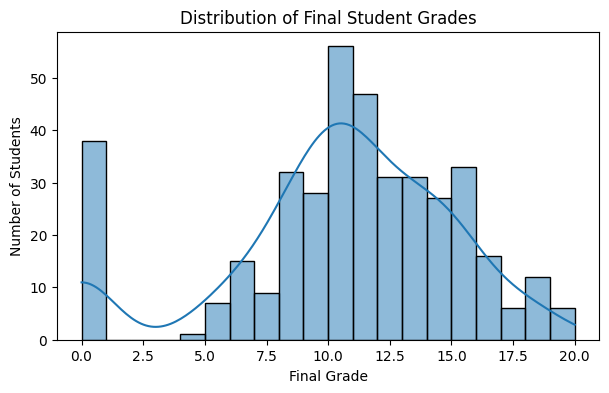

In [15]:

df.describe()

plt.figure(figsize=(7, 4))

sns.histplot(df['G3'], bins=20, kde=True)

plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()


In [16]:

df['Result'] = (df['G3'] >= 10).astype(int)

print(df[['G3', 'Result']].head(10))

print("\nPass/Fail Distribution:")
print(df['Result'].value_counts())


   G3  Result
0   6       0
1   6       0
2  10       1
3  15       1
4  10       1
5  15       1
6  11       1
7   6       0
8  19       1
9  15       1

Pass/Fail Distribution:
Result
1    265
0    130
Name: count, dtype: int64


In [20]:

X = df.drop(columns=['G3', 'Result'])
y = df['Result']

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("After encoding:", X.shape)

X.head()


Input features shape: (395, 32)
Target shape: (395,)
After encoding: (395, 41)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,0,1,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,1,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,1,0,1,1,0,0


In [21]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (316, 41)
Testing data: (79, 41)


In [22]:

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [23]:

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=5
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [24]:

def evaluate_model(y_true, predictions, model_name):

    print("\n", model_name)
    print("--------------------------")

    print("Accuracy:",
          accuracy_score(y_true, predictions))

    print("Precision:",
          precision_score(y_true, predictions, zero_division=0))

    print("Recall:",
          recall_score(y_true, predictions, zero_division=0))

    print("F1 Score:",
          f1_score(y_true, predictions, zero_division=0))


evaluate_model(y_test, dt_predictions, "Decision Tree")

evaluate_model(y_test, rf_predictions, "Random Forest")



 Decision Tree
--------------------------
Accuracy: 0.8607594936708861
Precision: 0.9772727272727273
Recall: 0.8113207547169812
F1 Score: 0.8865979381443299

 Random Forest
--------------------------
Accuracy: 0.8734177215189873
Precision: 0.9574468085106383
Recall: 0.8490566037735849
F1 Score: 0.9


In [25]:

results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],

    'Accuracy': [
        accuracy_score(y_test, dt_predictions),
        accuracy_score(y_test, rf_predictions)
    ],

    'Precision': [
        precision_score(y_test, dt_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, dt_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, dt_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ]
})

results


,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.860759,0.977273,0.811321,0.886598
1,Random Forest,0.873418,0.957447,0.849057,0.900000


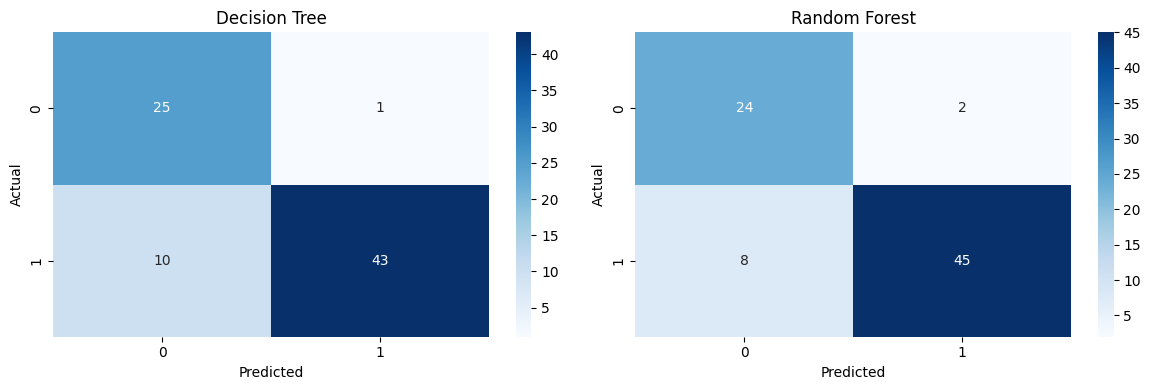

In [26]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, predictions, name in [
    (axes[0], dt_predictions, "Decision Tree"),
    (axes[1], rf_predictions, "Random Forest")
]:

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [27]:

import joblib

models_path = project_path + "/Models"

os.makedirs(models_path, exist_ok=True)

joblib.dump(dt_model, models_path + "/decision_tree_model.pkl")

joblib.dump(rf_model, models_path + "/random_forest_model.pkl")

joblib.dump(X.columns.tolist(), models_path + "/feature_columns.pkl")

print("Both models and feature columns saved successfully!")


Both models and feature columns saved successfully!


In [32]:
!pip install gradio

In [33]:
app_features = ['studytime', 'failures', 'absences', 'G1', 'G2']

X_app = df[app_features]
y_app = df['Result']

X_app_train, X_app_test, y_app_train, y_app_test = train_test_split(
    X_app,
    y_app,
    test_size=0.2,
    random_state=42,
    stratify=y_app
)

app_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=5
)

app_model.fit(X_app_train, y_app_train)

print("Application model trained successfully!")


Application model trained successfully!


In [36]:

def predict_student(studytime, failures, absences, G1, G2):

    student = pd.DataFrame([{
        'studytime': studytime,
        'failures': failures,
        'absences': absences,
        'G1': G1,
        'G2': G2
    }])

    prediction = app_model.predict(student)[0]

    probability = app_model.predict_proba(student)[0]

    confidence = max(probability) * 100

    if prediction == 1:
        result = "PASS"
    else:
        result = "FAIL"

    return f"Predicted Result: {result}\nConfidence: {confidence:.2f}%"


In [37]:
result = predict_student(
    studytime=2,
    failures=0,
    absences=4,
    G1=10,
    G2=12
)

print(result)

Predicted Result: PASS
Confidence: 91.23%


In [38]:

import gradio as gr

demo = gr.Interface(
    fn=predict_student,

    inputs=[
        gr.Slider(1, 4, value=2, step=1, label="Study Time"),
        gr.Slider(0, 4, value=0, step=1, label="Previous Failures"),
        gr.Number(value=4, label="Absences"),
        gr.Slider(0, 20, value=10, step=1, label="First Period Grade (G1)"),
        gr.Slider(0, 20, value=12, step=1, label="Second Period Grade (G2)")
    ],

    outputs=gr.Textbox(label="Prediction Result"),

    title="Student Performance Prediction System",

    description="Enter student academic details to predict Pass or Fail."
)

demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://11b0d931bdd8148c27.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [40]:
import os
import joblib

models_path = project_path + "/Models"
os.makedirs(models_path, exist_ok=True)

joblib.dump(app_model, models_path + "/student_prediction_app_model.pkl")
joblib.dump(app_features, models_path + "/app_features.pkl")

print("Application model saved successfully!")
print("Saved location:", models_path)

Application model saved successfully!
Saved location: /content/drive/MyDrive/Student_Performance_Prediction_ML/Models


In [41]:
print(os.listdir(models_path))

['decision_tree_model.pkl', 'random_forest_model.pkl', 'feature_columns.pkl', 'student_prediction_app_model.pkl', 'app_features.pkl']


In [42]:
import os
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results_path = project_path + "/Results"
os.makedirs(results_path, exist_ok=True)

results_df = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_test, dt_predictions),
        "Precision": precision_score(y_test, dt_predictions, zero_division=0),
        "Recall": recall_score(y_test, dt_predictions, zero_division=0),
        "F1 Score": f1_score(y_test, dt_predictions, zero_division=0)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_predictions),
        "Precision": precision_score(y_test, rf_predictions, zero_division=0),
        "Recall": recall_score(y_test, rf_predictions, zero_division=0),
        "F1 Score": f1_score(y_test, rf_predictions, zero_division=0)
    }
])

print(results_df)

results_df.to_csv(results_path + "/model_comparison.csv", index=False)

print("\nResults saved successfully!")

           Model  Accuracy  Precision    Recall  F1 Score
0  Decision Tree  0.860759   0.977273  0.811321  0.886598
1  Random Forest  0.873418   0.957447  0.849057  0.900000

Results saved successfully!


In [43]:
print(os.listdir(results_path))

['model_comparison.csv']


In [44]:
print(results_df.to_string(index=False))

        Model  Accuracy  Precision   Recall  F1 Score
Decision Tree  0.860759   0.977273 0.811321  0.886598
Random Forest  0.873418   0.957447 0.849057  0.900000


In [45]:
from sklearn.metrics import classification_report

dt_report = classification_report(
    y_test,
    dt_predictions,
    target_names=["Fail", "Pass"],
    zero_division=0
)

rf_report = classification_report(
    y_test,
    rf_predictions,
    target_names=["Fail", "Pass"],
    zero_division=0
)

print("DECISION TREE REPORT")
print(dt_report)

print("RANDOM FOREST REPORT")
print(rf_report)

with open(results_path + "/classification_reports.txt", "w") as f:
    f.write("DECISION TREE REPORT\n")
    f.write(dt_report)
    f.write("\nRANDOM FOREST REPORT\n")
    f.write(rf_report)

print("Classification reports saved successfully!")

DECISION TREE REPORT
              precision    recall  f1-score   support

        Fail       0.71      0.96      0.82        26
        Pass       0.98      0.81      0.89        53

    accuracy                           0.86        79
   macro avg       0.85      0.89      0.85        79
weighted avg       0.89      0.86      0.86        79

RANDOM FOREST REPORT
              precision    recall  f1-score   support

        Fail       0.75      0.92      0.83        26
        Pass       0.96      0.85      0.90        53

    accuracy                           0.87        79
   macro avg       0.85      0.89      0.86        79
weighted avg       0.89      0.87      0.88        79

Classification reports saved successfully!


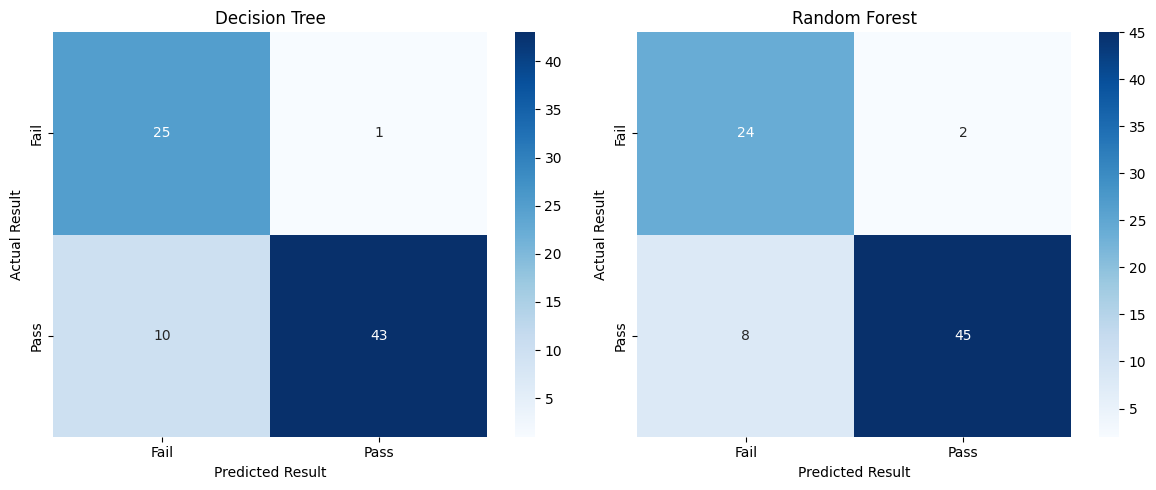

Confusion matrices saved successfully!


In [46]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    (dt_predictions, "Decision Tree"),
    (rf_predictions, "Random Forest")
]

for ax, (predictions, name) in zip(axes, models):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Fail", "Pass"],
        yticklabels=["Fail", "Pass"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Result")
    ax.set_ylabel("Actual Result")

plt.tight_layout()

plt.savefig(
    results_path + "/confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices saved successfully!")

In [47]:
print(os.listdir(results_path))

['model_comparison.csv', 'classification_reports.txt', 'confusion_matrices.png']


In [48]:
import zipfile
from google.colab import files

project_path = "/content/drive/MyDrive/Student_Performance_Prediction_ML"

models_path = project_path + "/Models"

zip_path = project_path + "/Models_For_Streamlit.zip"

with zipfile.ZipFile(zip_path, "w") as zip_file:

    zip_file.write(
        models_path + "/student_prediction_app_model.pkl",
        arcname="Models/student_prediction_app_model.pkl"
    )

    zip_file.write(
        models_path + "/app_features.pkl",
        arcname="Models/app_features.pkl"
    )

print("Model files packed successfully!")

files.download(zip_path)

Model files packed successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>